# Data Temporality (1 pt) — VisDrone video-aware detection

**Objective:** use detections from previous *consecutive* frames to improve predictions in the current frame. This notebook uses a **frozen, pretrained-on-VisDrone RetinaNet checkpoint** plus a lightweight IoU-based tracker, temporal score smoothing, and optional short-term detection propagation. **It never trains a detector.**

**Controlled comparison:** frame-independent RetinaNet vs several temporal settings on the **same images and same model weights**; tune temporal hyperparameters on *development clips*, select the winner, evaluate once on *different held-out clips*.

**Why not `STEP=5` here?** Earlier detector training sampled every 5th image. Temporal tracking needs adjacent real video frames: here we order frames by their clip and frame number, and reset tracking at video boundaries or numbering gaps. Do not interpret a global order of COCO image IDs as a video sequence.

Deliverables: metrics (overall, by size and density), per-clip changes, mAP gain/loss, precision/recall, speed overhead, before/after visual examples, model-selection CSV, configuration + limitations, a downloadable ZIP.

**Fair-NMS correction:** Before comparing temporal and single-frame results, we apply exactly the same extra class-wise NMS and max-detection cap to both branches. We also report native RetinaNet mAP separately as an NMS-only diagnostic; it is **not** the temporal baseline.


**Architecture compatibility note (v4):** The source repository replaces the torchvision v2 classification head with a fresh `RetinaNetClassificationHead` without GroupNorm. This notebook recreates that head before strictly loading the saved weights.


In [1]:
# 1. Kaggle setup and deterministic configuration
import os, sys, json, math, time, random, io, re, zipfile, hashlib, contextlib, subprocess, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)
RUN = Path('/kaggle/working/temporality_step1') if Path('/kaggle/working').exists() else Path('temporality_step1')
RUN.mkdir(exist_ok=True, parents=True)
DATA_ROOT_OVERRIDE = ''  # set only if Kaggle does not autodetect the data
HF_REPO = 'lilialania/visdrone-retinanet'
HF_CKPT = 'checkpoints/epoch_12.pt'  # RetinaNet baseline: step5, 12 epochs
SCORE_FLOOR = 0.01
MAX_DETECTIONS = 500
IOU_NMS = 0.50
# 0 => all held-out continuous frames; lower for a quick run
MAX_EVAL_IMAGES = 0
MAX_DEV_IMAGES = 0
NUM_DEV_CLIPS = 2
EVAL_TOP_CLIPS = 0  # 0 => all remaining clips, positive => bounded by clips
REUSE_PREDICTIONS = True
SAVE_PREDICTIONS_ON_HF = False   # avoids accidentally uploading video data; results stored in Kaggle Output
print('Outputs:', RUN)

Outputs: /kaggle/working/temporality_step1


In [2]:
# 2. Dependencies and Hugging Face authentication
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pycocotools', 'huggingface_hub'], check=True)
import torch, torchvision
from torchvision.models.detection import retinanet_resnet50_fpn_v2
from torchvision.ops import nms, box_iou
from torchvision.io import read_image, ImageReadMode
from huggingface_hub import hf_hub_download
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':print('GPU:', torch.cuda.get_device_name(0))
else: print('Warning: CPU mode will be much slower.')
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN').strip()
except Exception:
    HF_TOKEN = os.environ.get('HF_TOKEN', '').strip()
assert HF_TOKEN, 'Enable Kaggle secret HF_TOKEN for this notebook.'
print('torch:', torch.__version__, 'torchvision:', torchvision.__version__)

GPU: Tesla T4
torch: 2.11.0+cu130 torchvision: 0.26.0+cu130


In [3]:
# 3. Locate original COCO annotations and resolve images unambiguously
roots = ([Path(DATA_ROOT_OVERRIDE)] if DATA_ROOT_OVERRIDE else [])
roots += [Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026'), Path('/kaggle/input/multiple-object-video-detection-hw-2-ucu-ai-2026')]
if Path('/kaggle/input').exists():
    roots += [p.parent.parent for p in Path('/kaggle/input').glob('**/val/annotations_coco.json')]
root = next((p for p in roots if (p/'val/annotations_coco.json').is_file()), None)
assert root is not None, 'VisDrone COCO val annotations not found. Set DATA_ROOT_OVERRIDE.'
VAL_DIR = root/'val'
coco = COCO(str(VAL_DIR/'annotations_coco.json'))
print('Dataset:',root,'images:',len(coco.imgs),'GT categories:',coco.cats)

# Only one file-system scan. Basenames (e.g., 0000001.jpg) repeat across clips,
# hence resolve full relative paths rather than silently pairing the wrong frame.
paths = [p for p in (VAL_DIR/'images').rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png'}]
by_rel = {p.relative_to(VAL_DIR).as_posix():p for p in paths}
by_tail = defaultdict(list)
for p in paths:
    by_tail['/'.join(p.parts[-2:])].append(p)
    by_tail[p.name].append(p)
def image_file(record):
    rel = str(record['file_name']).replace('\\','/').lstrip('./')
    tries = [rel, 'images/'+rel, rel.removeprefix('val/')]
    for t in tries:
        if t in by_rel:return by_rel[t]
    # last two path components identify clip and frame
    parts = rel.split('/')
    for suffix in ('/'.join(parts[-2:]), parts[-1]):
        matched=by_tail.get(suffix, [])
        if len(matched)==1:return matched[0]
    raise FileNotFoundError(f'Ambiguous or missing image path: {rel}')

frame_rows=[]
for iid, rec in coco.imgs.items():
    p=image_file(rec)
    clip=p.parent.name
    m=re.search(r'(\d+)$',p.stem)
    assert m, f'No numeric frame identifier: {p}'
    frame_rows.append({'id':int(iid), 'clip':clip,'frame':int(m.group(1)),'path':str(p), 'file_name':rec['file_name']})
frames=pd.DataFrame(frame_rows).sort_values(['clip','frame']).reset_index(drop=True)
assert not frames.duplicated(['clip','frame']).any(), 'Duplicate video frame numbering; inspect COCO / paths.'
print('Detected clips:',frames["clip"].nunique(), 'images:',len(frames))
display(frames.groupby('clip').agg(images=('id','size'),first=('frame','min'),last=('frame','max')).head(12))


loading annotations into memory...
Done (t=0.57s)
creating index...
index created!
Dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 images: 2846 GT categories: {1: {'id': 1, 'name': 'person'}, 2: {'id': 2, 'name': 'bicycle'}, 3: {'id': 3, 'name': 'car'}, 4: {'id': 4, 'name': 'van'}, 5: {'id': 5, 'name': 'truck'}, 6: {'id': 6, 'name': 'tricycle'}, 7: {'id': 7, 'name': 'bus'}, 8: {'id': 8, 'name': 'motor'}}
Detected clips: 7 images: 2846


,images,first,last
clip,,,
uav0000086_00000_v,464,1,464
uav0000117_02622_v,349,1,349
uav0000137_00458_v,233,1,233
uav0000182_00000_v,363,1,363
uav0000268_05773_v,978,1,978
uav0000305_00000_v,184,1,184
uav0000339_00001_v,275,1,275


In [4]:
# 4. Make real consecutive sequences and development / held-out video split
# A gap > 1 resets the tracker (do not propagate across missing intermediate frames).
frames['gap']=frames.groupby('clip')['frame'].diff()
frames['segment_idx']=((frames['gap'].isna()) | (frames['gap']!=1)).groupby(frames['clip']).cumsum()
frames['segment']=frames['clip']+'__'+frames['segment_idx'].astype(str)
# Access the 'clip' COLUMN with brackets: DataFrame.clip is a pandas METHOD.
assert 'clip' in frames.columns and frames['clip'].notna().all()
clips=sorted(frames['clip'].unique())
assert len(clips)>=2, 'Need >=2 independent video clips for leak-free development/test split.'
rng=np.random.RandomState(SEED); shuffled=list(rng.permutation(clips))
n_dev = min(max(1,NUM_DEV_CLIPS),len(clips)-1)
dev_clips=set(shuffled[:n_dev]); test_clips=set(shuffled[n_dev:])
if EVAL_TOP_CLIPS > 0:test_clips=set(sorted(test_clips)[:EVAL_TOP_CLIPS])
def choose(df, cap=0):
    # Cap by COMPLETE video segments, never skip every fifth frame inside a segment.
    if cap <= 0:return df.copy().reset_index(drop=True)
    pieces=[]; k=0
    for _,group in df.groupby('segment',sort=True):
        if k+len(group)>cap:continue
        pieces.append(group);k+=len(group)
    if not pieces:raise ValueError('MAX_*_IMAGES below the length of any complete segment. Increase cap.')
    return pd.concat(pieces,ignore_index=True)
dev=choose(frames[frames["clip"].isin(dev_clips)],MAX_DEV_IMAGES)
test=choose(frames[frames["clip"].isin(test_clips)],MAX_EVAL_IMAGES)
assert not set(dev["clip"])&set(test["clip"])
assert len(dev) and len(test)
print('DEV:',len(dev),'images;',len(dev_clips),'clips | HOLDOUT:',len(test),'images;',len(test_clips),'clips')
print('dev segments:',dev.segment.nunique(),'held-out segments:',test.segment.nunique())
manifest={'seed':SEED,'dev_clips':sorted(dev_clips),'test_clips':sorted(test_clips), 'dev_image_ids':dev.id.astype(int).tolist(), 'test_image_ids':test.id.astype(int).tolist(), 'max_eval_images':MAX_EVAL_IMAGES,'max_dev_images':MAX_DEV_IMAGES}
(RUN/'split_manifest.json').write_text(json.dumps(manifest,indent=2))


DEV: 813 images; 2 clips | HOLDOUT: 2033 images; 5 clips
dev segments: 2 held-out segments: 5


27692

## Method: one-stage detector + temporal links

1. **Baseline:** run frozen RetinaNet independently on every frame.
2. **Associate:** for each category, greedily pair new detections to the previous frame's tracks if their box IoU exceeds `match_iou` (one-to-one greedy matching).
3. **Smooth confidence:** for a matched pair, use `new_score = (1-alpha)*current_score + alpha*previous_score`. Optionally blend coordinates by a small amount to reduce jitter.
4. **Recover missed objects:** if a previously high-confidence track is unmatched, optionally propagate its box to the **next consecutive frame only** at a decayed score. We use **the identical class-wise post-NMS (same IoU threshold and max detections) in BOTH the single-frame baseline and temporal branch**. The baseline receives no temporal information. This isolates the effect of temporal linking/rescoring/propagation from the effect of adding another NMS operation.
5. **Reset** state at every clip boundary or frame gap. No future frames and no ground-truth boxes are used for temporal predictions.

This is **post-detection temporal aggregation**, not recurrent model training and not optical-flow-based motion compensation. It can improve stability and recall when the camera/object motion is small, but may cause ghost boxes after objects leave the scene, duplicate tracks, or drift during rapid camera movement. Those cases are measured below.

In [5]:
# 5. Load *actual* trained RetinaNet checkpoint, fail loudly on architecture mismatch
ckpt_path=Path(hf_hub_download(repo_id=HF_REPO,filename=HF_CKPT,repo_type='model',token=HF_TOKEN))
ckpt=torch.load(ckpt_path,map_location='cpu',weights_only=False)  # only load this TRUSTED own checkpoint
assert isinstance(ckpt,dict) and 'model' in ckpt, f'Unexpected checkpoint format: {type(ckpt)}'
state={k.removeprefix('module.'):v for k,v in ckpt['model'].items()}
cls_key=next((k for k in state if k.endswith('classification_head.cls_logits.weight')),None)
assert cls_key is not None, 'Missing RetinaNet classification head'
num_anchors=9
num_classes=state[cls_key].shape[0]//num_anchors
assert num_classes==9, f'Expected 9 class logits including background, got {num_classes}'
print('Checkpoint epoch:',ckpt.get('epoch'),'sizes:',ckpt.get('min_size'),ckpt.get('max_size'),'classes:',num_classes)
# IMPORTANT: the repo trained with a fresh RetinaNetClassificationHead (Conv+ReLU, no GroupNorm).
# The default torchvision RetinaNet v2 head uses Conv+GroupNorm+ReLU instead,
# so its state_dict keys do not match. Reconstruct the exact repository head.
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
model=retinanet_resnet50_fpn_v2(weights=None,weights_backbone=None,
    min_size=ckpt.get('min_size',640),max_size=ckpt.get('max_size',1280),
    detections_per_img=MAX_DETECTIONS)
in_channels=model.backbone.out_channels
actual_num_anchors=model.anchor_generator.num_anchors_per_location()[0]
assert actual_num_anchors == num_anchors, (actual_num_anchors, num_anchors)
model.head.classification_head=RetinaNetClassificationHead(
    in_channels, actual_num_anchors, num_classes)
# Strict loading verifies that every parameter has the architecture expected by this checkpoint.
model.load_state_dict(state,strict=True)
model.score_thresh=SCORE_FLOOR
model.topk_candidates=1000
model.detections_per_img=MAX_DETECTIONS
model=model.to(DEVICE).eval()
assert all(1<=c<=8 for c in coco.cats),'Expected VisDrone categories 1..8'
print('Checkpoint loaded STRICTLY; ready for frame inference.')


checkpoints/epoch_12.pt: reconstructing file:   0%|          |  0.00B /  291MB            

checkpoints/epoch_12.pt: downloading bytes:           |  0.00B            

Checkpoint epoch: 12 sizes: 640 1280 classes: 9
Checkpoint loaded STRICTLY; ready for frame inference.


In [6]:
# 6. Frozen model predictions, cached locally for resumability
BASE_PRED_FILE=RUN/'retinanet_raw_predictions.json'
IMAGE_IDS=set(dev.id.astype(int))|set(test.id.astype(int))
if REUSE_PREDICTIONS and BASE_PRED_FILE.exists():
    payload=json.loads(BASE_PRED_FILE.read_text())
    assert payload.get('checkpoint')==HF_CKPT and payload.get('score_floor')==SCORE_FLOOR, 'Raw cache belongs to different detector settings'
    cached={int(k):v for k,v in payload['predictions'].items()}
else:cached={}
missing=IMAGE_IDS-set(cached)
print('Cached:',len(IMAGE_IDS)-len(missing),'remaining:',len(missing))
t0=time.perf_counter(); per_image_times=[]
@torch.inference_mode()
def infer_one(path):
    image=read_image(path,mode=ImageReadMode.RGB).float().div(255).to(DEVICE)
    if DEVICE.type=='cuda':torch.cuda.synchronize()
    start=time.perf_counter(); pred=model([image])[0]
    if DEVICE.type=='cuda':torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    out=[]
    for box,sc,lab in zip(pred['boxes'].cpu().tolist(),pred['scores'].cpu().tolist(),pred['labels'].cpu().tolist()):
        if lab not in coco.cats:continue
        out.append({'box':[float(x) for x in box],'score':float(sc),'label':int(lab),'source':'detector'})
    return out,elapsed
for i,r in enumerate(frames[frames.id.isin(missing)].itertuples(index=False),1):
    pred,elapsed=infer_one(r.path)
    cached[int(r.id)]=pred;per_image_times.append(elapsed)
    if i%50==0 or i==len(missing):
        BASE_PRED_FILE.write_text(json.dumps({'checkpoint':HF_CKPT,'score_floor':SCORE_FLOOR,'predictions':cached}))
        print(f'Predicted {i}/{len(missing)} images; raw cache saved')
BASE_PRED_FILE.write_text(json.dumps({'checkpoint':HF_CKPT,'score_floor':SCORE_FLOOR,'predictions':cached}))
print('Raw detections available:',len(cached),'new inference sec:',round(time.perf_counter()-t0,1))
print('Detector mean inference ms/image (newly computed only):', round(1000*np.mean(per_image_times),2) if per_image_times else 'cached')


Cached: 0 remaining: 2846
Predicted 50/2846 images; raw cache saved
Predicted 100/2846 images; raw cache saved
Predicted 150/2846 images; raw cache saved
Predicted 200/2846 images; raw cache saved
Predicted 250/2846 images; raw cache saved
Predicted 300/2846 images; raw cache saved
Predicted 350/2846 images; raw cache saved
Predicted 400/2846 images; raw cache saved
Predicted 450/2846 images; raw cache saved
Predicted 500/2846 images; raw cache saved
Predicted 550/2846 images; raw cache saved
Predicted 600/2846 images; raw cache saved
Predicted 650/2846 images; raw cache saved
Predicted 700/2846 images; raw cache saved
Predicted 750/2846 images; raw cache saved
Predicted 800/2846 images; raw cache saved
Predicted 850/2846 images; raw cache saved
Predicted 900/2846 images; raw cache saved
Predicted 950/2846 images; raw cache saved
Predicted 1000/2846 images; raw cache saved
Predicted 1050/2846 images; raw cache saved
Predicted 1100/2846 images; raw cache saved
Predicted 1150/2846 images

In [7]:
# 7. Temporal algorithm (causal, per-class, one-to-one matching, no cross-video leakage)
def bbox_iou(a,b):
    x1=max(a[0],b[0]); y1=max(a[1],b[1]); x2=min(a[2],b[2]); y2=min(a[3],b[3]);
    inter=max(0,x2-x1)*max(0,y2-y1)
    area1=max(0,a[2]-a[0])*max(0,a[3]-a[1]);area2=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(area1+area2-inter,1e-9)

def classwise_suppress(detections, iou=IOU_NMS, max_dets=MAX_DETECTIONS):
    res=[]
    for label in sorted({d['label'] for d in detections}):
        ds=[d for d in detections if d['label']==label]
        if not ds:continue
        boxes=torch.tensor([d['box'] for d in ds],dtype=torch.float32)
        scores=torch.tensor([d['score'] for d in ds],dtype=torch.float32)
        idx=nms(boxes,scores,iou).tolist()
        res.extend(ds[j] for j in idx)
    return sorted(res,key=lambda d:d['score'],reverse=True)[:max_dets]

def prepare_single_frame_baseline(df, original_predictions, iou=IOU_NMS):
    """Same optional class-wise NMS and detection cap as the temporal branch.

    The underlying torchvision RetinaNet predictions already passed its native NMS.
    Applying the identical extra post-processing to both arms eliminates an
    asymmetric NMS comparison. No scores, boxes, or tracking state are altered.
    """
    return {int(iid):classwise_suppress(original_predictions[int(iid)],iou)
            for iid in df.id}

def temporal_predict(df, base, alpha=0.0, match_iou=.3, propagate=False, prop_min=.50,
                    decay=.65, box_blend=0.0, prop_nms=IOU_NMS):
    output={}; tracks=[]; prev_seg=None; last_frame=None
    for rec in df.itertuples(index=False):
        if rec.segment!=prev_seg or (last_frame is not None and rec.frame!=last_frame+1):tracks=[]
        prev_seg,last_frame=rec.segment,rec.frame
        dets=[dict(d) for d in base[int(rec.id)]]
        edges=[]
        # Vectorized IoU matching: significantly faster than pairwise Python loops
        # for densely populated VisDrone scenes.
        if dets and tracks:
            for label in sorted(set(d['label'] for d in dets)&set(t['label'] for t in tracks)):
                di_idx=[i for i,d in enumerate(dets) if d['label']==label and d['score']>=.03]
                ti_idx=[i for i,t in enumerate(tracks) if t['label']==label and t['score']>=.03]
                if not di_idx or not ti_idx:continue
                a=torch.tensor([dets[i]['box'] for i in di_idx],dtype=torch.float32)
                b=torch.tensor([tracks[j]['box'] for j in ti_idx],dtype=torch.float32)
                overlaps=box_iou(a,b)
                ij=(overlaps>=match_iou).nonzero(as_tuple=False)
                edges.extend((float(overlaps[ii,jj]),di_idx[ii],ti_idx[jj]) for ii,jj in ij.tolist())
        edges.sort(reverse=True)
        used_d=set();used_t=set();matches=[]
        for _,di,ti in edges:
            if di in used_d or ti in used_t:continue
            used_d.add(di);used_t.add(ti);matches.append((di,ti))
        for di,ti in matches:
            d,t=dets[di],tracks[ti]
            d['score']=(1-alpha)*d['score']+alpha*t['score']
            d['box']=[(1-box_blend)*x+box_blend*y for x,y in zip(d['box'],t['box'])]
            d['source']='matched'
        newly=[dict(d) for d in dets]
        if propagate:
            for ti,t in enumerate(tracks):
                if ti not in used_t and t['score']>=prop_min:
                    newly.append({'box':list(t['box']), 'label':t['label'],
                                  'score':min(.999,t['score']*decay),'source':'propagated'})
        # Propagations survive for this frame ONLY; they cannot be propagated again.
        # IMPORTANT: use the SAME post-NMS threshold and top-K as the baseline.
        valid=classwise_suppress(newly,prop_nms)
        tracks=[dict(d) for d in valid if d['source']!='propagated']
        output[int(rec.id)]=valid
    return output

def coco_results(preds):
    records=[]
    for iid,det in preds.items():
        for d in det:
            x1,y1,x2,y2=d['box']
            if x2<=x1 or y2<=y1:continue
            records.append({'image_id':int(iid),'category_id':int(d['label']),
                'bbox':[float(x1),float(y1),float(x2-x1),float(y2-y1)],'score':float(d['score'])})
    return records

def evaluate_coco(df,preds):
    ids=[int(x) for x in df.id]
    recs=coco_results({i:preds[i] for i in ids})
    if not recs:return {k:0.0 for k in ['mAP','AP50','AP75','AP_small','AP_medium','AP_large','AR100']}
    with contextlib.redirect_stdout(io.StringIO()):
        ev=COCOeval(coco,coco.loadRes(recs),'bbox')
        ev.params.imgIds=ids;ev.params.maxDets=[1,100,MAX_DETECTIONS]
        ev.evaluate();ev.accumulate()
    p=ev.eval['precision'];ar=ev.eval['recall']
    def avg(arr):
        arr=np.asarray(arr); good=arr[arr>-1]
        return float(good.mean()) if len(good) else float('nan')
    return {'mAP':avg(p[:,:,:,0,2]),'AP50':avg(p[0,:,:,0,2]),'AP75':avg(p[5,:,:,0,2]),
            'AP_small':avg(p[:,:,:,1,2]),'AP_medium':avg(p[:,:,:,2,2]),'AP_large':avg(p[:,:,:,3,2]),
            'AR100':avg(ar[:,:,0,1])}


In [8]:
# 8. Development-video search (NO evaluation-image labels used to select settings)
raw_dev=prepare_single_frame_baseline(dev,cached)
raw_dev_score=evaluate_coco(dev,raw_dev)
# Diagnostic only: quantify the effect of extra NMS itself; do not use for selection.
native_dev={int(i):cached[int(i)] for i in dev.id}
native_dev_score=evaluate_coco(dev,native_dev)
print('Extra-NMS-only delta on DEV:',round(raw_dev_score['mAP']-native_dev_score['mAP'],6))
print('Development baseline (identical NMS as temporal):',raw_dev_score)
CANDIDATES={
    'rescore_20':{'alpha':.20,'match_iou':.3,'propagate':False},
    'rescore_40':{'alpha':.40,'match_iou':.3,'propagate':False},
    'propagate': {'alpha':.25,'match_iou':.3,'propagate':True,'prop_min':.65,'decay':.70},
    'smooth_boxes':{'alpha':.30,'match_iou':.4,'box_blend':.12,'propagate':False},
}
dev_records=[{'method':'raw_detector',**raw_dev_score}]
for name,config in CANDIDATES.items():
    pred=temporal_predict(dev,cached,**config)
    metrics=evaluate_coco(dev,pred)
    dev_records.append({'method':name,**metrics})
    print('DEV',name,'mAP',round(metrics['mAP'],5),'delta',round(metrics['mAP']-raw_dev_score['mAP'],5))
dev_df=pd.DataFrame(dev_records).sort_values('mAP',ascending=False)
dev_df.to_csv(RUN/'development_search.csv',index=False)
display(dev_df.round(4))
# select on dev only. If no candidate improves, baseline remains honest winner.
win=dev_df.iloc[0]['method']; selected_config=CANDIDATES.get(win)
print('Selected by DEVELOPMENT mAP:',win,selected_config)
(RUN/'selected_temporal_params.json').write_text(json.dumps({'selected':win,'config':selected_config,'baseline_dev':raw_dev_score,'candidates':CANDIDATES},indent=2))


Extra-NMS-only delta on DEV: -0.0
Development baseline (identical NMS as temporal): {'mAP': 0.16759222538780744, 'AP50': 0.34172664028203287, 'AP75': 0.15502060491493275, 'AP_small': 0.035245770434136396, 'AP_medium': 0.12064299062539444, 'AP_large': 0.2679407540356261, 'AR100': 0.3229266392179521}
DEV rescore_20 mAP 0.16949 delta 0.0019
DEV rescore_40 mAP 0.17142 delta 0.00383
DEV propagate mAP 0.1701 delta 0.00251
DEV smooth_boxes mAP 0.17088 delta 0.00329


,method,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR100
2,rescore_40,0.1714,0.3495,0.1585,0.0352,0.1231,0.2758,0.3229
4,smooth_boxes,0.1709,0.3484,0.1603,0.0360,0.1234,0.2744,0.3213
3,propagate,0.1701,0.3468,0.1575,0.0352,0.1223,0.2738,0.3230
1,rescore_20,0.1695,0.3458,0.1567,0.0352,0.1220,0.2733,0.3229
0,raw_detector,0.1676,0.3417,0.1550,0.0352,0.1206,0.2679,0.3229


Selected by DEVELOPMENT mAP: rescore_40 {'alpha': 0.4, 'match_iou': 0.3, 'propagate': False}


855

In [9]:
# 9. Final held-out evaluation: baseline, every temporal variant, selected result
base_test=prepare_single_frame_baseline(test,cached)
# Native RetinaNet (without second NMS) is retained ONLY for the NMS-only ablation.
native_test={int(i):cached[int(i)] for i in test.id}
native_score=evaluate_coco(test,native_test)
held_records=[]; held_predictions={'raw_detector':base_test}
start=time.perf_counter()
held_records.append({'method':'raw_detector',**evaluate_coco(test,base_test)})
for name,config in CANDIDATES.items():
    t0=time.perf_counter()
    pred=temporal_predict(test,cached,**config)
    elapsed=time.perf_counter()-t0
    held_predictions[name]=pred
    held_records.append({'method':name,'postprocess_ms_per_image':elapsed/len(test)*1000,**evaluate_coco(test,pred)})
results=pd.DataFrame(held_records)
baseline_mAP=float(results.loc[results.method=='raw_detector','mAP'].iloc[0])
print('Held-out native RetinaNet mAP (diagnostic only):',round(native_score['mAP'],6))
print('Held-out NMS-only delta:',round(baseline_mAP-native_score['mAP'],6))
(RUN/'nms_only_ablation.json').write_text(json.dumps({
    'native_retinanet':native_score,
    'matched_post_nms_retinanet':results.loc[results.method=='raw_detector'].iloc[0].drop('method').to_dict(),
    'native_vs_extra_nms_delta_mAP':baseline_mAP-native_score['mAP'],
    'note':'Temporal effect is measured against the matched post-NMS RetinaNet; native detector is an ablation only.'
},indent=2))
results['delta_mAP']=results.mAP-baseline_mAP
results.loc[results.method=='raw_detector','postprocess_ms_per_image']=0.0
results.to_csv(RUN/'heldout_metrics.csv',index=False)
print('Final held-out test images:',len(test),'selected by development:',win)
display(results.sort_values('mAP',ascending=False).round(5))
print('Selected method held-out delta mAP:',round(float(results.loc[results.method==win,'delta_mAP'].iloc[0]),6))
# Always report result as observed, including a negative outcome.


Held-out native RetinaNet mAP (diagnostic only): 0.147713
Held-out NMS-only delta: 0.0
Final held-out test images: 2033 selected by development: rescore_40


,method,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR100,postprocess_ms_per_image,delta_mAP
2,rescore_40,0.15047,0.28434,0.14058,0.03894,0.13861,0.35264,0.31472,7.64606,0.00276
1,rescore_20,0.14942,0.28222,0.13970,0.03845,0.13760,0.34891,0.31472,7.62665,0.00171
3,propagate,0.14926,0.28200,0.13932,0.03855,0.13750,0.34943,0.31477,7.19906,0.00154
4,smooth_boxes,0.14911,0.28318,0.13692,0.03828,0.13713,0.35030,0.31310,6.52926,0.00140
0,raw_detector,0.14771,0.27915,0.13785,0.03778,0.13608,0.34284,0.31471,0.00000,0.00000


Selected method held-out delta mAP: 0.002758


In [10]:
# 10. Small, medium, large + dense/sparse subsets (HELD-OUT only)
counts=pd.Series({iid:sum(1 for ann in coco.imgToAnns.get(int(iid),[]) if not ann.get('iscrowd',0)) for iid in test.id},name='objects')
threshold=int(max(1,np.ceil(counts.quantile(.75))))
print('Dense threshold: >=',threshold,'objects per frame (held-out 75th percentile)')
small_ids=set(counts[counts<threshold].index); dense_ids=set(counts[counts>=threshold].index)
rows=[]
for group_name,ids in [('sparse',small_ids),('dense',dense_ids)]:
    subset=test[test.id.isin(ids)]
    if len(subset)<2:continue
    for name in ['raw_detector',win] if win!='raw_detector' else ['raw_detector']:
        m=evaluate_coco(subset,held_predictions[name]);rows.append({'density':group_name,'method':name,'images':len(subset),'threshold':threshold,**m})
density_df=pd.DataFrame(rows)
density_df.to_csv(RUN/'density_results.csv',index=False)
display(density_df.round(4))


Dense threshold: >= 47 objects per frame (held-out 75th percentile)


,density,method,images,threshold,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR100
0,sparse,raw_detector,1473,47,0.1534,0.2478,0.1673,0.0408,0.1524,0.3919,0.3353
1,sparse,rescore_40,1473,47,0.1561,0.2525,0.1701,0.0418,0.1540,0.3999,0.3354
2,dense,raw_detector,560,47,0.1906,0.3691,0.1734,0.0468,0.1724,0.4323,0.2974
3,dense,rescore_40,560,47,0.1953,0.3770,0.1788,0.0492,0.1765,0.4676,0.2974


,clip,frames,raw_mAP,temporal_mAP,gain
0,uav0000137_00458_v,233,0.2154,0.2179,0.0025
1,uav0000182_00000_v,363,0.1157,0.1190,0.0033
2,uav0000268_05773_v,978,0.0974,0.1014,0.0040
3,uav0000305_00000_v,184,0.2079,0.2128,0.0049
4,uav0000339_00001_v,275,0.2173,0.2228,0.0055


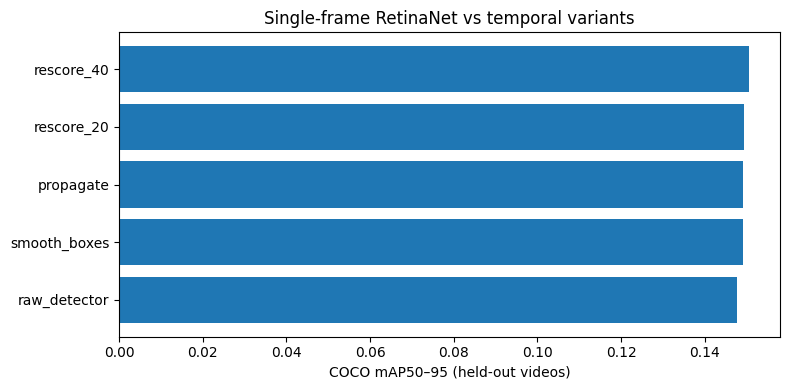

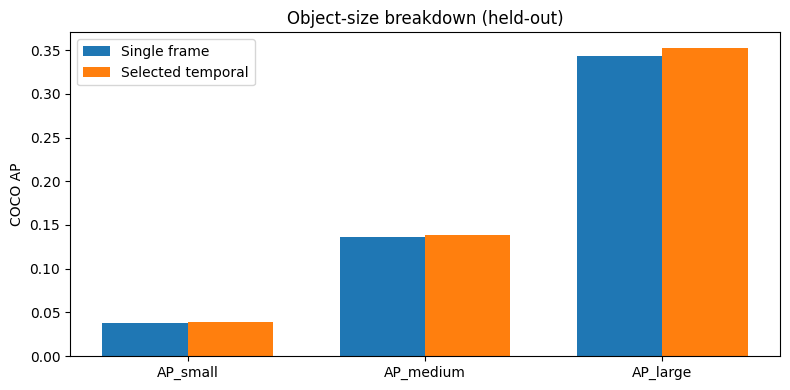

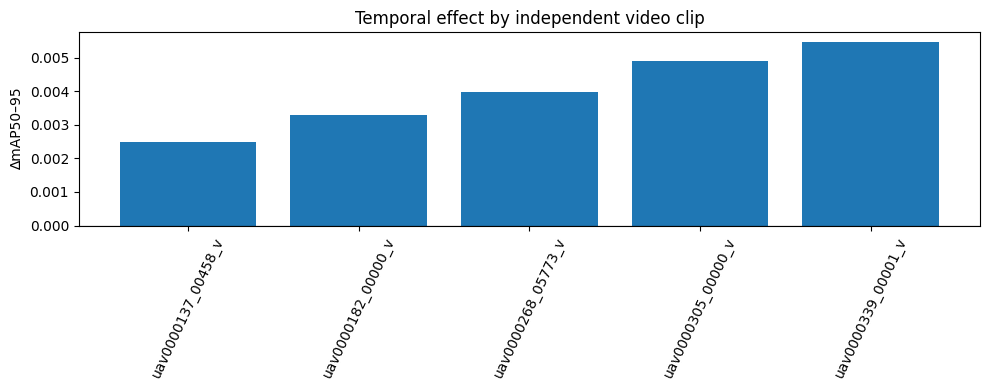

In [11]:
# 11. Per-clip improvements and model diagnostics
per_clip=[]
for clip,sub in test.groupby('clip'):
    if len(sub)<2:continue
    bm=evaluate_coco(sub,held_predictions['raw_detector'])
    tm=evaluate_coco(sub,held_predictions[win])
    per_clip.append({'clip':clip,'frames':len(sub),'raw_mAP':bm['mAP'],'temporal_mAP':tm['mAP'],'gain':tm['mAP']-bm['mAP']})
clip_df=pd.DataFrame(per_clip)
clip_df.to_csv(RUN/'per_clip_results.csv',index=False)
if not clip_df.empty:display(clip_df.sort_values('gain').round(4))

fig,ax=plt.subplots(figsize=(8,4))
plot_df=results[['method','mAP']].sort_values('mAP')
ax.barh(plot_df.method,plot_df.mAP)
ax.set_xlabel('COCO mAP50–95 (held-out videos)');ax.set_title('Single-frame RetinaNet vs temporal variants')
plt.tight_layout();plt.savefig(RUN/'temporal_map_comparison.png',dpi=170);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
metric_names=['AP_small','AP_medium','AP_large']
a=results.set_index('method').loc['raw_detector',metric_names].astype(float)
b=results.set_index('method').loc[win,metric_names].astype(float)
x=np.arange(3);ax.bar(x-.18,a,width=.36,label='Single frame');ax.bar(x+.18,b,width=.36,label='Selected temporal')
ax.set_xticks(x,metric_names);ax.set_ylabel('COCO AP');ax.set_title('Object-size breakdown (held-out)');ax.legend()
plt.tight_layout();plt.savefig(RUN/'temporal_ap_by_size.png',dpi=170);plt.show()

if not clip_df.empty:
    fig,ax=plt.subplots(figsize=(10,4));ax.bar(clip_df["clip"].astype(str),clip_df.gain)
    ax.axhline(0,color='black',linewidth=.8);ax.tick_params(axis='x',rotation=65)
    ax.set_ylabel('∆mAP50–95');ax.set_title('Temporal effect by independent video clip')
    plt.tight_layout();plt.savefig(RUN/'per_clip_gain.png',dpi=170);plt.show()


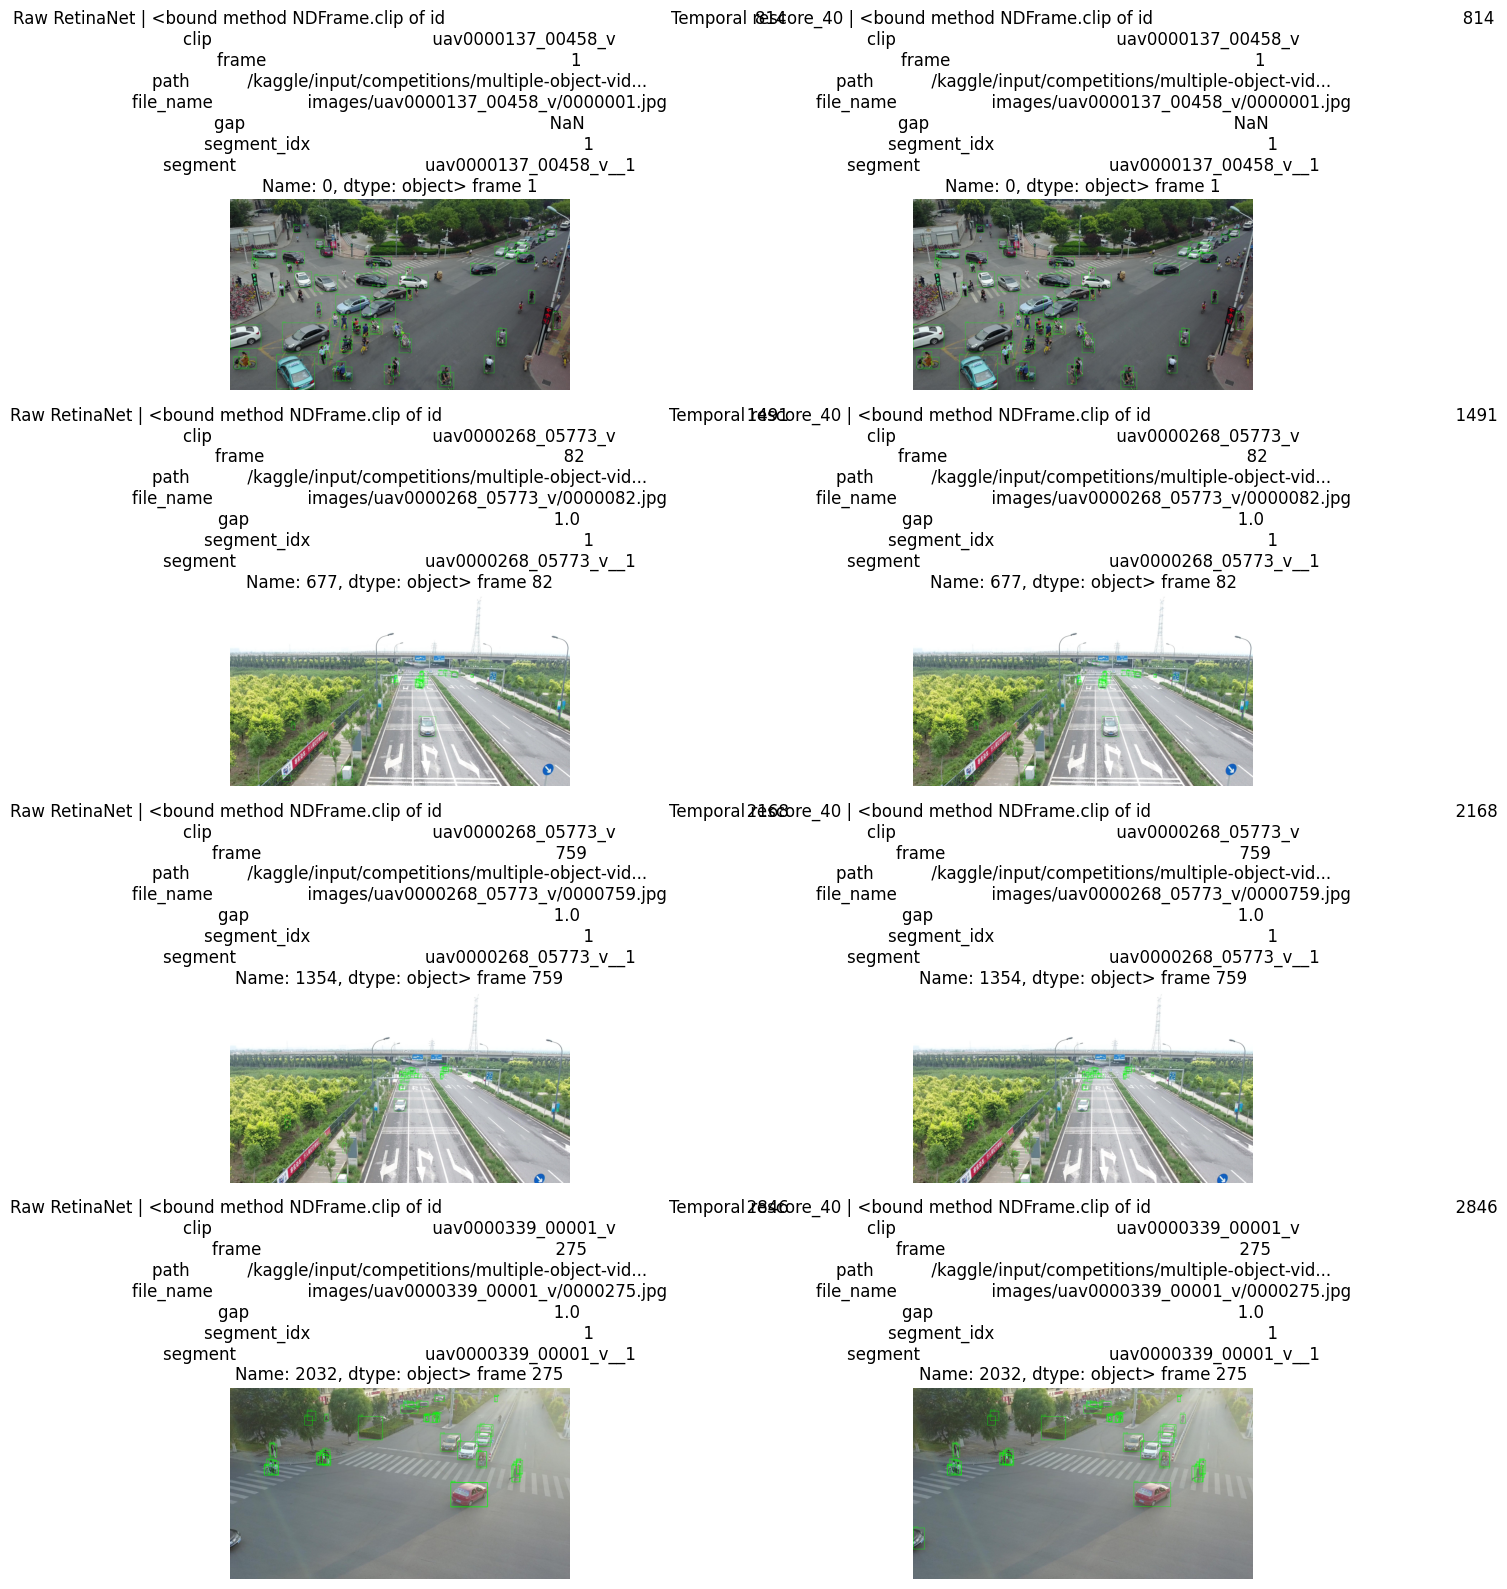

In [12]:
# 12. Before/after qualitative examples (same frame, same trained detector)
from PIL import Image,ImageDraw

def draw_frame(path,dets,limit=60):
    im=Image.open(path).convert('RGB')
    dr=ImageDraw.Draw(im)
    for d in sorted(dets,key=lambda d:d['score'],reverse=True)[:limit]:
        box=[int(v) for v in d['box']]
        color='orange' if d.get('source')=='propagated' else 'lime'
        dr.rectangle(box,outline=color,width=2)
        dr.text((box[0],max(0,box[1]-11)),f"{d['label']}:{d['score']:.2f}",fill=color)
    im.thumbnail((760,520))
    return im

# Show diverse frames, not a hand-picked high-performing example.
examples=test.iloc[np.linspace(0,len(test)-1,min(4,len(test))).astype(int)]
fig,axs=plt.subplots(len(examples),2,figsize=(14,4*len(examples)),squeeze=False)
for row,(idx,rec) in enumerate(examples.iterrows()):
    for j,(name,preds) in enumerate([('Raw RetinaNet',held_predictions['raw_detector']),('Temporal '+win,held_predictions[win])]):
        axs[row,j].imshow(draw_frame(rec.path,preds[int(rec.id)]));axs[row,j].set_title(f'{name} | {rec.clip} frame {rec.frame}')
        axs[row,j].axis('off')
plt.tight_layout();plt.savefig(RUN/'qualitative_comparison.png',dpi=130);plt.show()


## Interpretation and limitations (read before submitting)

- **Causal temporal use:** every current-frame prediction can depend only on the previous **contiguous** frame's predictions, never on future frames or ground truth.
- **What improves?** Compare selected method to the single-frame baseline using `heldout_metrics.csv`. Improved **AP50** can mean recovered or strengthened marginal detections; degraded AP75 can indicate propagated boxes are less accurately localized.
- **Small objects:** inspect `AP_small`, `AP_medium`, `AP_large`; aerial objects are tiny and can move by a large fraction of their box width between frames.
- **Dense scenes:** inspect `density_results.csv` and per-clip metrics; overlapping same-class objects can be swapped during greedy IoU association. Propagation can create ghost boxes and inflate false positives.
- **Camera motion:** no optical flow/homography is used. Fast drone motion invalidates box matching; restrict propagation length, raise matching IoU, or add motion compensation in a further experiment.
- **Fairness:** both arms use the same RetinaNet, frames, **and additional post-NMS settings**; the single-frame branch has no tracking, whereas temporal branches link previous detections. The native RetinaNet score is reported separately as an NMS-only ablation to document whether post-NMS itself changes AP. Hyperparameters are selected on **different video clips** from those in held-out evaluation.
- **Model training:** none was performed here; this is a post-processing experiment using a model trained in the earlier anchor-based section.
- **Video annotations:** video continuity is inferred from directory and numeric filename; inspect a few sequences for correctness. Frame gaps reset tracking. If data are subsampled, the temporal effect can be less meaningful.
- **A negative outcome is valid.** Clearly report failure to improve, including which density and object-size strata regress. Do not claim improvement merely because propagation was implemented.

In [13]:
# 13. Machine-readable report + compact ZIP (exclude raw checkpoint & images)
selected_row=results.set_index('method').loc[win].to_dict()
raw_row=results.set_index('method').loc['raw_detector'].to_dict()
report={
    'task':'Data Temporality', 'dataset':'VisDrone', 'checkpoint':f'{HF_REPO}/{HF_CKPT}',
    'protocol':{'dev_clips':sorted(dev_clips),'heldout_clips':sorted(test_clips),
        'dev_frames':len(dev),'heldout_frames':len(test),'consecutive_frames':True,
        'score_floor':SCORE_FLOOR,'max_detections':MAX_DETECTIONS,'nms_threshold':IOU_NMS,'matched_extra_nms_both_arms':True},
    'selected_from_dev':win,'temporal_settings':selected_config,
    'baseline_heldout':raw_row,'native_detector_diagnostic':native_score,'temporal_heldout':selected_row,
    'delta_mAP':float(selected_row['mAP']-raw_row['mAP']),
    'improves_mAP':bool(selected_row['mAP']>raw_row['mAP'])
}
(RUN/'final_report.json').write_text(json.dumps(report,indent=2))
text=f"""DATA TEMPORALITY — RESULTS
Frozen model: {HF_REPO}/{HF_CKPT}
Temporal strategy: IoU matching, optional EMA score smoothing / 1-frame propagation, per-clip reset
Fair comparison: identical additional class-wise NMS and max detections in BOTH arms
Native RetinaNet (no extra NMS) mAP50–95: {native_score['mAP']:.6f}
Dev videos: {len(dev_clips)} ({len(dev)} frames); held-out videos: {len(test_clips)} ({len(test)} frames)
Temporal configuration selected on development clips: {win}: {selected_config}
Matched-NMS single-frame RetinaNet held-out mAP50–95: {raw_row['mAP']:.6f}
Selected temporal held-out mAP50–95: {selected_row['mAP']:.6f}
Delta mAP: {report['delta_mAP']:+.6f}
Raw / temporal AP_small: {raw_row['AP_small']:.4f} / {selected_row['AP_small']:.4f}
Raw / temporal AP_medium: {raw_row['AP_medium']:.4f} / {selected_row['AP_medium']:.4f}
Raw / temporal AP_large: {raw_row['AP_large']:.4f} / {selected_row['AP_large']:.4f}
Temporal postprocessing overhead: {selected_row.get('postprocess_ms_per_image',0):.3f} ms/frame (excludes detector)
Dense threshold >= {threshold} objects/frame.
Interpretation: {'held-out mAP improved' if report['improves_mAP'] else 'no held-out mAP gain; report this as a limitation'}.
Potential failures: camera motion, identity switches, hallucinated propagated boxes, inaccurate boxes for tiny objects.
This is temporal inference, not extra model training. Ground truth is used only for evaluation and dev selection.
"""
(RUN/'report.txt').write_text(text);print(text)
# Include summary artifacts, plus raw detection cache as separate output but not in ZIP (may be large).
zip_path=RUN.parent/'temporality_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in RUN.glob('*'):
        if path.is_file() and path.name!='retinanet_raw_predictions.json':z.write(path,arcname=path.name)
print('ZIP ready:',zip_path,'size MB:',round(zip_path.stat().st_size/1e6,2))
print('No detector training was performed.')


DATA TEMPORALITY — RESULTS
Frozen model: lilialania/visdrone-retinanet/checkpoints/epoch_12.pt
Temporal strategy: IoU matching, optional EMA score smoothing / 1-frame propagation, per-clip reset
Fair comparison: identical additional class-wise NMS and max detections in BOTH arms
Native RetinaNet (no extra NMS) mAP50–95: 0.147713
Dev videos: 2 (813 frames); held-out videos: 5 (2033 frames)
Temporal configuration selected on development clips: rescore_40: {'alpha': 0.4, 'match_iou': 0.3, 'propagate': False}
Matched-NMS single-frame RetinaNet held-out mAP50–95: 0.147713
Selected temporal held-out mAP50–95: 0.150471
Delta mAP: +0.002758
Raw / temporal AP_small: 0.0378 / 0.0389
Raw / temporal AP_medium: 0.1361 / 0.1386
Raw / temporal AP_large: 0.3428 / 0.3526
Temporal postprocessing overhead: 7.646 ms/frame (excludes detector)
Dense threshold >= 47 objects/frame.
Interpretation: held-out mAP improved.
Potential failures: camera motion, identity switches, hallucinated propagated boxes, inacc